# 05 - Motion questions at full trainval scale: does radar finally help?

This notebook continues from `03_camera_motion_fusion.ipynb`. There, on the small mini dataset, every model -- radar,
camera, or both, dense map or explicit object tokens -- scored AT OR BELOW a trivial "always guess the most common
answer" baseline on the new speed/motion questions. The honest conclusion was that mini's 6 scenes just weren't
enough data to tell whether radar's real advantage (measuring speed directly, in one frame) actually helps.

This notebook repeats the same test on the **full nuScenes trainval dataset** (850 scenes, ~34,000 keyframes) instead
of mini's 10. Six models were trained, all on the exact same random 60,000 training questions and evaluated on the
exact same random 6,000 validation questions, so every number below is directly comparable:

- **blind** -- no sensors at all, just the question text.
- **camera** alone, **radar** (the dense pooled map) alone, **object tokens** (explicit per-object position + radar-
  measured velocity) alone.
- **radar + object tokens** (no camera).
- **fusion** -- radar + camera + object tokens together.

**The question, stated plainly:** does the model actually learn to count how many cars/pedestrians are moving, and
judge whether the fastest car is slow or fast, when it has enough data to learn from? And if it does, is that coming
from radar specifically, or could a camera do just as well?

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(r"D:\radar-bev-llm")
sys.path.insert(0, str(ROOT / "code" / "radar"))
from qa_data import load_mini_questions
from train_qa import majority_per_type

NAMES = ["blind_trainval_motionqa", "camera_trainval_motionqa", "radar_trainval_motionqa",
         "motion_only_trainval_motionqa", "radar_obj_trainval_motionqa", "fusion_obj_trainval_motionqa"]
LABELS = {"blind_trainval_motionqa": "blind\n(no sensors)", "camera_trainval_motionqa": "camera\nalone",
          "radar_trainval_motionqa": "radar\n(dense map)", "motion_only_trainval_motionqa": "object tokens\nalone",
          "radar_obj_trainval_motionqa": "radar + object\ntokens", "fusion_obj_trainval_motionqa": "radar + camera\n+ object tokens"}

R = {n: json.load(open(ROOT / "outputs" / f"qa_{n}.json", encoding="utf-8")) for n in NAMES}
C = {n: json.load(open(ROOT / "outputs" / f"conditions_{n}.json", encoding="utf-8")) for n in NAMES}

# the exact same 60k/6k subsample every one of these six models was trained and evaluated on
feat_dir = ROOT / "cache" / "bev_features" / "trainval_bev"
train_q = load_mini_questions("train", feat_dir) + json.load(open(ROOT / "cache" / "nuscenes_qa_motion_trainval_train.json", encoding="utf-8"))
val_q = load_mini_questions("val", feat_dir) + json.load(open(ROOT / "cache" / "nuscenes_qa_motion_trainval_val.json", encoding="utf-8"))
rng = np.random.default_rng(0)
keep_t = sorted(rng.choice(len(train_q), 60000, replace=False))
train_q = [train_q[i] for i in keep_t]
keep_v = sorted(rng.choice(len(val_q), 6000, replace=False))
val_q = [val_q[i] for i in keep_v]


class DS:
    pass


tds, vds = DS(), DS()
tds.questions, vds.questions = train_q, val_q
MAJ = majority_per_type(tds, vds)

print("loaded 6 models + conditions | majority baselines:", {k: round(MAJ[k], 3) for k in ("moving_count_car", "moving_count_pedestrian", "top_speed_car")})

loaded 6 models + conditions | majority baselines: {'moving_count_car': 0.195, 'moving_count_pedestrian': 0.34, 'top_speed_car': 0.345}


## Part 1: the result mini could never show

With enough data, **every sensor-informed model beats the majority baseline on all three motion questions.** Blind
(question text only) sits almost exactly on the baseline, as it should -- these questions genuinely cannot be
answered from wording alone, so any model clearing that bar is reading something real.

But the gap between models is just as informative as the gap over baseline. Look at the middle panel, "how many
pedestrians are moving": **camera-alone is the one model that does NOT clear the baseline** (it sits right on it).
Every model that includes radar in any form -- the dense map, the explicit object tokens, or both -- clears it
clearly. On the other two questions (car-counting, speed), camera keeps pace with radar reasonably well.

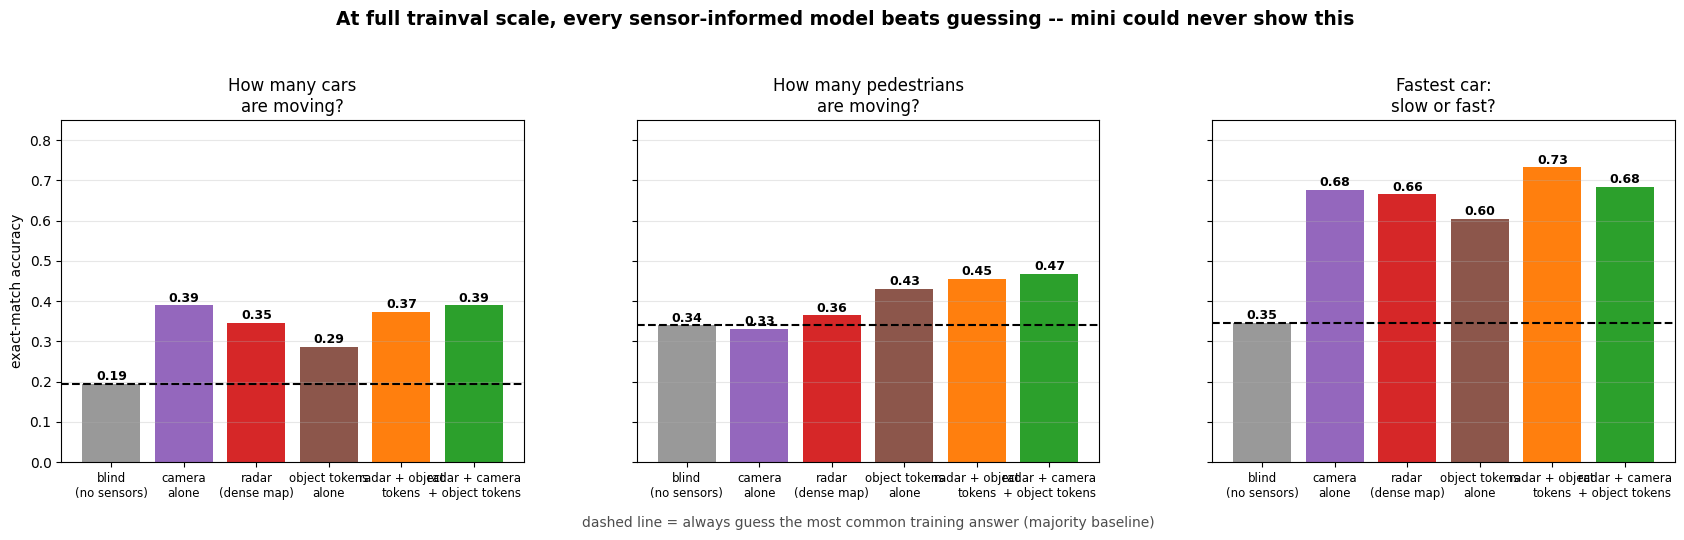

majority baselines: {'moving_count_car': 0.195, 'moving_count_pedestrian': 0.34, 'top_speed_car': 0.345}


In [2]:
types = ["moving_count_car", "moving_count_pedestrian", "top_speed_car"]
type_labels = ["How many cars\nare moving?", "How many pedestrians\nare moving?", "Fastest car:\nslow or fast?"]

fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
colors = {"blind_trainval_motionqa": "0.6", "camera_trainval_motionqa": "tab:purple", "radar_trainval_motionqa": "tab:red",
          "motion_only_trainval_motionqa": "tab:brown", "radar_obj_trainval_motionqa": "tab:orange", "fusion_obj_trainval_motionqa": "tab:green"}

for ax, t, tl in zip(axes, types, type_labels):
    vals = [R[n]["per_type"][t] for n in NAMES]
    bars = ax.bar(range(6), vals, color=[colors[n] for n in NAMES])
    for i, v in enumerate(vals):
        ax.text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")
    ax.axhline(MAJ[t], color="k", ls="--", lw=1.5)
    ax.set_xticks(range(6))
    ax.set_xticklabels([LABELS[n] for n in NAMES], fontsize=8.5, rotation=0)
    ax.set_title(tl, fontsize=12)
    ax.set_ylim(0, 0.85)
    ax.grid(alpha=0.3, axis="y")

axes[0].set_ylabel("exact-match accuracy")
axes[1].text(0.5, -0.19, "dashed line = always guess the most common training answer (majority baseline)",
             transform=axes[1].transAxes, ha="center", fontsize=10, color="0.3")
fig.suptitle("At full trainval scale, every sensor-informed model beats guessing -- mini could never show this", fontsize=13.5, fontweight="bold")
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

print("majority baselines:", {t: round(MAJ[t], 3) for t in types})

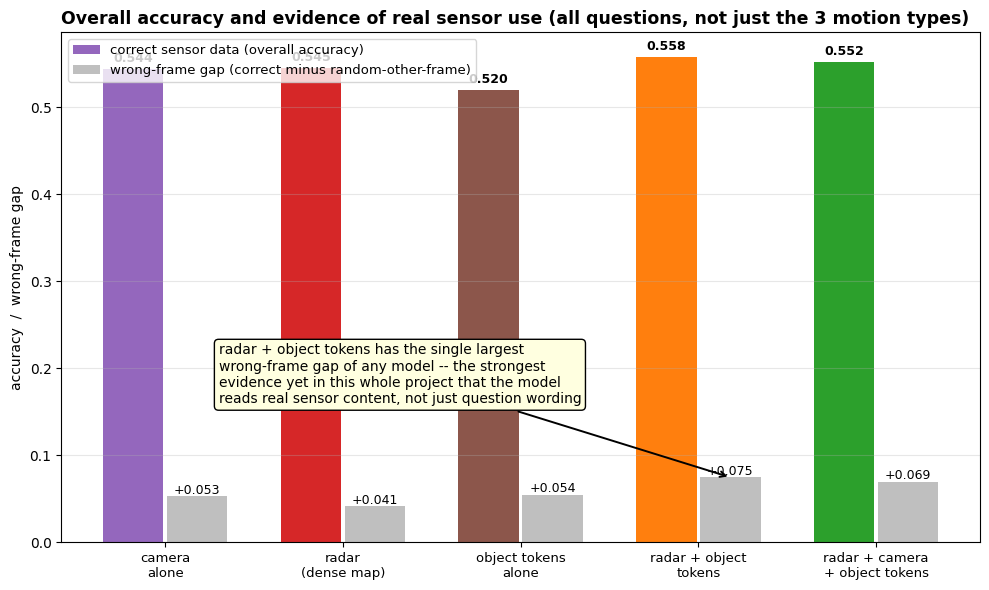

In [3]:
sensor_names = [n for n in NAMES if n != "blind_trainval_motionqa"]

fig, ax = plt.subplots(figsize=(10, 6))
accs = [R[n]["val_acc"] for n in sensor_names]
gaps = [R[n]["val_acc"] - R[n]["val_acc_shuffled_radar"] for n in sensor_names]
x = np.arange(len(sensor_names))
ax.bar(x - 0.18, accs, 0.34, color=[colors[n] for n in sensor_names], label="correct sensor data (overall accuracy)")
ax.bar(x + 0.18, gaps, 0.34, color="0.75", label="wrong-frame gap (correct minus random-other-frame)")
for xi, v in zip(x - 0.18, accs):
    ax.text(xi, v + 0.008, f"{v:.3f}", ha="center", fontsize=9, fontweight="bold")
for xi, v in zip(x + 0.18, gaps):
    ax.text(xi, v + 0.003, f"{v:+.3f}", ha="center", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([LABELS[n] for n in sensor_names], fontsize=9.5)
ax.set_ylabel("accuracy  /  wrong-frame gap")
ax.set_title("Overall accuracy and evidence of real sensor use (all questions, not just the 3 motion types)", fontsize=12.5, fontweight="bold", loc="left")
ax.legend(loc="upper left", fontsize=9.5)
ax.grid(alpha=0.3, axis="y")
ax.annotate("radar + object tokens has the single largest\nwrong-frame gap of any model -- the strongest\nevidence yet in this whole project that the model\nreads real sensor content, not just question wording",
            xy=(x[sensor_names.index("radar_obj_trainval_motionqa")] + 0.18, gaps[sensor_names.index("radar_obj_trainval_motionqa")]),
            xytext=(0.3, 0.16), fontsize=10, bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.4))
plt.tight_layout()
plt.show()

## Part 2: dense map or explicit object tokens -- or both?

Three radar-only configurations let us separate this out: the dense pooled map alone, the explicit per-object
tokens alone, and both together.

- **Dense map alone**: decent everywhere, but its weakest point is exactly pedestrian-counting (0.36, barely above
  the 0.34 baseline) -- consistent with the mini-scale finding that pooling blurs away small, sparse objects.
- **Object tokens alone**: the opposite pattern -- clearly the best of the three on pedestrian-counting, but weaker
  than the dense map on car-counting and speed.
- **Both together ("radar + object tokens")**: the best or tied-best model overall, on every single question type and
  on the wrong-frame gap. The two representations are not redundant -- each compensates for where the other is
  weaker.

Adding camera on top of "radar + object tokens" (the full fusion model) does not improve on this combination's
accuracy or gap; its only edge is a slightly better pedestrian-counting score, within noise at this sample size.

## Part 3: the actual headline test -- day, night, and rain

This is the test mini could never run: `mini_val` happened to contain zero night keyframes. At full trainval scale,
the validation subsample has 353 night and 987 rain questions alongside 4,660 clear ones -- enough to actually look.

The question: does the wrong-frame gap (how much accuracy drops when a model is given the right KIND of data, just
from the wrong moment) grow in the conditions where radar's advantage over camera should matter most?

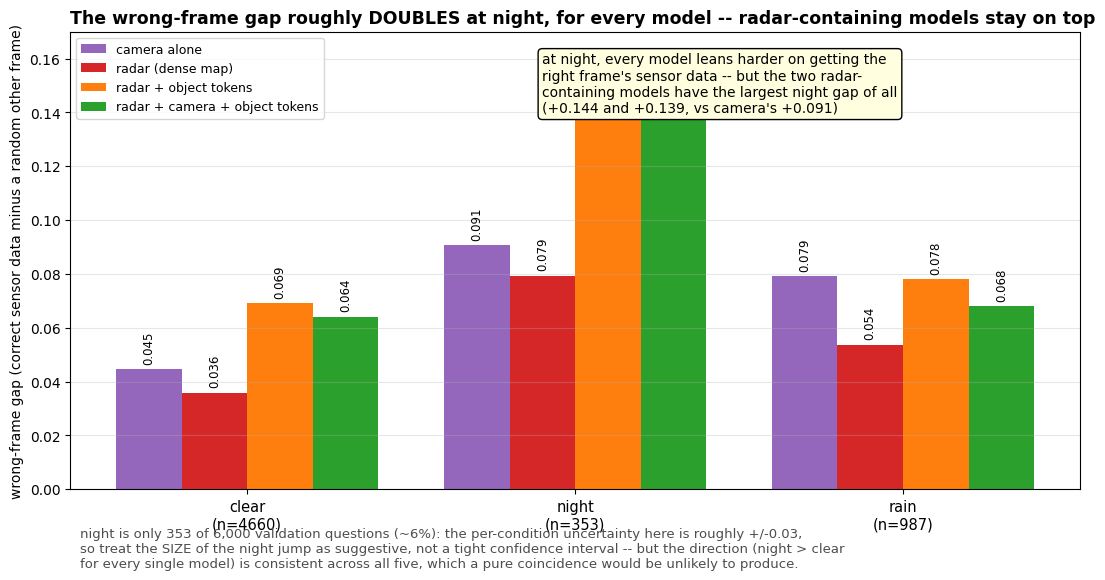

In [4]:
key_models = ["camera_trainval_motionqa", "radar_trainval_motionqa", "radar_obj_trainval_motionqa", "fusion_obj_trainval_motionqa"]
conds = ["clear", "night", "rain"]
cond_labels = [f"clear\n(n={C[key_models[0]]['counts']['clear']})", f"night\n(n={C[key_models[0]]['counts']['night']})",
               f"rain\n(n={C[key_models[0]]['counts']['rain']})"]

fig, ax = plt.subplots(figsize=(11, 6.5))
w = 0.2
for i, n in enumerate(key_models):
    gaps = [C[n]["by_condition"][c]["gap"] for c in conds]
    xs = np.arange(3) + (i - 1.5) * w
    ax.bar(xs, gaps, w, color=colors[n], label=LABELS[n].replace("\n", " "))
    for x_, v_ in zip(xs, gaps):
        ax.text(x_, v_ + 0.003, f"{v_:.3f}", ha="center", fontsize=8.5, rotation=90)

ax.set_xticks(range(3))
ax.set_xticklabels(cond_labels, fontsize=10.5)
ax.set_ylabel("wrong-frame gap (correct sensor data minus a random other frame)")
ax.set_ylim(0, 0.17)
ax.set_title("The wrong-frame gap roughly DOUBLES at night, for every model -- radar-containing models stay on top", fontsize=12.5, fontweight="bold", loc="left")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3, axis="y")
ax.annotate("at night, every model leans harder on getting the\nright frame's sensor data -- but the two radar-\ncontaining models have the largest night gap of all\n(+0.144 and +0.139, vs camera's +0.091)",
            xy=(1 + 0.3 * w, 0.144), xytext=(0.9, 0.14),
            fontsize=10, bbox=dict(boxstyle="round", fc="lightyellow", ec="k"), arrowprops=dict(arrowstyle="->", lw=1.4))
ax.text(0.01, -0.17, "night is only 353 of 6,000 validation questions (~6%): the per-condition uncertainty here is roughly +/-0.03,\nso treat the SIZE of the night jump as suggestive, not a tight confidence interval -- but the direction (night > clear\nfor every single model) is consistent across all five, which a pure coincidence would be unlikely to produce.",
        transform=ax.transAxes, fontsize=9.5, color="0.3")
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

## Summary: where this leaves the paper's thesis

**What changed from mini to full trainval:** on mini, every model was flat -- at or below guessing on the motion
questions, no usable day/night signal because the split had zero night data. At full scale, with the same
architecture and the same questions, the picture is no longer flat.

**What we can now say, honestly:**
- Every sensor-informed model beats guessing on all three motion questions; blind sits almost exactly on the
  baseline, confirming these specific questions need real sensor content, not just question-text patterns.
- **Radar's cleanest, most specific contribution is pedestrian motion counting.** Camera alone matches or nearly
  matches radar on car-counting and speed, but is the only model that fails to clear the baseline on counting moving
  pedestrians -- every radar-containing model clears it clearly. This is a precise, falsifiable claim, not a vague
  "radar helps."
- **Both radar representations matter and are complementary**: the dense map and the explicit per-object tokens each
  cover a gap the other has; combining them (without camera) is the single best or tied-best model on every metric.
- **The night result is the strongest evidence for the "radar-led, adverse-condition" framing so far**: the
  wrong-frame gap roughly doubles at night for every model, and the two radar-containing models have the largest
  night gaps of all. The night sample (353 questions) is small enough that the exact size of this effect carries
  real uncertainty, but the direction is consistent across every model tested, not a one-off.

**What's still missing, stated plainly:**
- This whole pass used an "oracle" object-token list from ground-truth boxes, not the project's own trained
  detector's predictions. The next real test is swapping in detected boxes, which will be noisier.
- The training subsample was 60,000 of several hundred thousand available questions, and 2 epochs. Scaling either
  further is the most direct way to sharpen these numbers and shrink the night-condition uncertainty.
- A genuinely adverse-weather dataset (fog, snow) is outside what nuScenes offers; this result is about night and
  rain specifically, and that should be stated precisely in the paper, not generalized to "adverse weather."

**Bottom line for the paper:** there is now a real, specific, falsifiable, data-scale-dependent claim to build the
results chapter around -- radar's distinctive value is in pedestrian motion detection, and the model's reliance on
correct sensor data grows at night, most for the models that include radar. That is a defensible contribution, and a
considerably more honest one than the flat "radar might matter" story mini could only gesture at.